In [3]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")
import numpy as np
import matplotlib.pyplot as plt
from GNAR import *
from NLSWE import *
from network import *
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
import json
with open('CovidEdges.json') as f:
    d = json.load(f)
    covid_edges = {key: [x-1 for x in d[key]] for key in range(len(d))}

with open('CovidDists.json') as f:
    d = json.load(f)
    covid_dists = {key: np.array(d[key]) for key in range(len(d))}

covid_vts = np.exp(np.genfromtxt("CovidVTS.csv",skip_header=1))-1
covid_vts_log = np.genfromtxt("CovidVTS.csv",skip_header=1)
covid_network = Network(covid_edges,covid_dists)
covid_network_0 = Network(covid_edges,covid_dists,gamma=0.)
from copy import deepcopy

# Simulation

In [4]:
def random_network_dist(N,a=1/4,b=3/4):
    edges = {}
    dists = {}
    indices = [i for i in range(N)]
    for i in range(N):
        indices.remove(i)
        if isinstance(a,int) and isinstance(b,int):
            edge_n = random.randint(a,b)
        else:
            edge_n = random.randint(int(N*a),int(N*b))
        edges[i] = random.sample(indices,edge_n)
        indices.append(i)
        dists[i] = np.random.exponential(size=len(edges[i]))
    return Network(edges,dists,symmetry=False)

In [5]:


def support_confusion(true_W,est_W,tol=1e-8):
    mask = ~np.eye(true_W.shape[0],dtype=bool)
    true_support = np.abs(true_W[mask])>tol
    est_support = np.abs(est_W[mask])>tol
    tp = np.sum(true_support&est_support)
    tn = np.sum(~true_support&~est_support)
    fp = np.sum(~true_support&est_support)
    fn = np.sum(true_support&~est_support)
    return np.array([[tn,fp],[fn,tp]])

def support_metrics(cm):
    tn,fp = cm[0].astype(float)
    fn,tp = cm[1].astype(float)
    tpr = tp/(tp+fn) if tp+fn>0 else np.nan
    fpr = fp/(fp+tn) if fp+tn>0 else np.nan
    precision = tp/(tp+fp) if tp+fp>0 else np.nan
    f1 = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn>0 else np.nan
    mcc_den = np.sqrt((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))
    mcc = (tp*tn-fp*fn)/mcc_den if mcc_den>0 else np.nan
    return np.array([tpr,fpr,precision,f1,mcc])

## N=64

In [21]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=64
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,1,2)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|██████████████████████████████████████████████████████████████████████████████| 100/100 [2:07:03<00:00, 76.24s/it]


Transition matrix SSE
NLSWE: 0.0724 (0.0164)
Oracle GNAR: 0.0010 (0.0009)
VARLasso: 0.3400 (0.0292)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[386597   7052]
 [   826   8725]]
Mean confusion matrix
[[3865.97   70.52]
 [   8.26   87.25]]
TPR: 0.9141 (0.0345)
FPR: 0.0179 (0.0104)
Precision: 0.5852 (0.1279)
F1: 0.7045 (0.0969)
MCC: 0.7183 (0.0837)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[352642  41007]
 [   667   8884]]
Mean confusion matrix
[[3526.42  410.07]
 [   6.67   88.84]]
TPR: 0.9306 (0.0313)
FPR: 0.1042 (0.0206)
Precision: 0.1825 (0.0290)
F1: 0.3041 (0.0402)
MCC: 0.3855 (0.0364)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.009484
NLSWE std: 0.001309
NLSWE min: 0.007000
NLSWE max: 0.012400
NLSWE counts:
(array([0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.008 , 0.0082, 0.0084,
       0.0086, 0.0088, 0.009 , 0.0092, 0.0094, 0.0096, 0.0098, 0.01  ,
       0.0104, 0.0106, 0.0108, 0.011 , 0.0112, 0.0114, 0.0116, 0.012 ,
       0.0122, 0.0124]), array([ 1,

In [22]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=64
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,2,3)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|██████████████████████████████████████████████████████████████████████████████| 100/100 [1:59:56<00:00, 71.96s/it]


Transition matrix SSE
NLSWE: 0.1891 (0.0243)
Oracle GNAR: 0.0015 (0.0016)
VARLasso: 0.4666 (0.0373)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[373956  13269]
 [  3461  12514]]
Mean confusion matrix
[[3739.56  132.69]
 [  34.61  125.14]]
TPR: 0.7838 (0.0403)
FPR: 0.0343 (0.0147)
Precision: 0.5080 (0.1005)
F1: 0.6085 (0.0665)
MCC: 0.6078 (0.0579)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[336633  50592]
 [  2801  13174]]
Mean confusion matrix
[[3366.33  505.92]
 [  28.01  131.74]]
TPR: 0.8250 (0.0317)
FPR: 0.1306 (0.0280)
Precision: 0.2126 (0.0362)
F1: 0.3362 (0.0443)
MCC: 0.3756 (0.0391)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.008018
NLSWE std: 0.000638
NLSWE min: 0.006800
NLSWE max: 0.009800
NLSWE counts:
(array([0.0068, 0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.008 , 0.0082,
       0.0084, 0.0086, 0.0088, 0.009 , 0.0092, 0.0094, 0.0098]), array([ 1,  7,  6,  6, 15, 12, 11, 10,  9,  6,  6,  6,  3,  1,  1],
      dtype=int64))

VARLasso mean: 0.006996

In [23]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=64
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,3,4)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|██████████████████████████████████████████████████████████████████████████████| 100/100 [2:30:25<00:00, 90.26s/it]


Transition matrix SSE
NLSWE: 0.2731 (0.0269)
Oracle GNAR: 0.0012 (0.0016)
VARLasso: 0.5412 (0.0335)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[365300  15529]
 [  7458  14913]]
Mean confusion matrix
[[3653.    155.29]
 [  74.58  149.13]]
TPR: 0.6667 (0.0398)
FPR: 0.0408 (0.0159)
Precision: 0.5082 (0.0889)
F1: 0.5705 (0.0515)
MCC: 0.5502 (0.0501)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[326791  54038]
 [  6080  16291]]
Mean confusion matrix
[[3267.91  540.38]
 [  60.8   162.91]]
TPR: 0.7284 (0.0380)
FPR: 0.1419 (0.0280)
Precision: 0.2366 (0.0334)
F1: 0.3554 (0.0361)
MCC: 0.3571 (0.0334)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.007734
NLSWE std: 0.000521
NLSWE min: 0.006600
NLSWE max: 0.009400
NLSWE counts:
(array([0.0066, 0.0068, 0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.008 ,
       0.0082, 0.0084, 0.0086, 0.0088, 0.009 , 0.0094]), array([ 1,  2,  5, 13, 17, 13, 14, 10, 14,  2,  5,  1,  2,  1],
      dtype=int64))

VARLasso mean: 0.006658
VARLasso st

In [24]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=64
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,4,5)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|██████████████████████████████████████████████████████████████████████████████| 100/100 [2:36:35<00:00, 93.96s/it]


Transition matrix SSE
NLSWE: 0.3346 (0.0382)
Oracle GNAR: 0.0012 (0.0010)
VARLasso: 0.5850 (0.0426)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[358201  16269]
 [ 12687  16043]]
Mean confusion matrix
[[3582.01  162.69]
 [ 126.87  160.43]]
TPR: 0.5587 (0.0512)
FPR: 0.0434 (0.0194)
Precision: 0.5194 (0.0914)
F1: 0.5297 (0.0367)
MCC: 0.4966 (0.0402)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[317956  56514]
 [ 10254  18476]]
Mean confusion matrix
[[3179.56  565.14]
 [ 102.54  184.76]]
TPR: 0.6433 (0.0405)
FPR: 0.1509 (0.0339)
Precision: 0.2523 (0.0354)
F1: 0.3601 (0.0339)
MCC: 0.3292 (0.0328)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.007702
NLSWE std: 0.000496
NLSWE min: 0.006800
NLSWE max: 0.008800
NLSWE counts:
(array([0.0068, 0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.008 , 0.0082,
       0.0084, 0.0086, 0.0088]), array([ 3,  5, 14, 20, 14, 12,  8, 10,  5,  6,  3], dtype=int64))

VARLasso mean: 0.006468
VARLasso std: 0.000619
VARLasso min: 0.005000
VARLass

In [25]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=64
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,5,6)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|██████████████████████████████████████████████████████████████████████████████| 100/100 [2:38:48<00:00, 95.28s/it]


Transition matrix SSE
NLSWE: 0.3763 (0.0456)
Oracle GNAR: 0.0013 (0.0013)
VARLasso: 0.5996 (0.0383)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[352230  15833]
 [ 18262  16875]]
Mean confusion matrix
[[3522.3   158.33]
 [ 182.62  168.75]]
TPR: 0.4802 (0.0427)
FPR: 0.0430 (0.0171)
Precision: 0.5343 (0.0846)
F1: 0.4992 (0.0260)
MCC: 0.4580 (0.0342)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[314245  53818]
 [ 14983  20154]]
Mean confusion matrix
[[3142.45  538.18]
 [ 149.83  201.54]]
TPR: 0.5736 (0.0357)
FPR: 0.1462 (0.0283)
Precision: 0.2773 (0.0347)
F1: 0.3717 (0.0267)
MCC: 0.3141 (0.0283)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.007646
NLSWE std: 0.000483
NLSWE min: 0.006600
NLSWE max: 0.010200
NLSWE counts:
(array([0.0066, 0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.008 , 0.0082,
       0.0084, 0.0086, 0.009 , 0.0102]), array([ 1,  3, 15, 29, 15, 16,  7,  6,  2,  4,  1,  1], dtype=int64))

VARLasso mean: 0.006502
VARLasso std: 0.000599
VARLasso min: 0.00

In [26]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=64
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,6,7)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|██████████████████████████████████████████████████████████████████████████████| 100/100 [2:11:05<00:00, 78.65s/it]


Transition matrix SSE
NLSWE: 0.4165 (0.0520)
Oracle GNAR: 0.0014 (0.0013)
VARLasso: 0.6276 (0.0405)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[345094  16582]
 [ 23837  17687]]
Mean confusion matrix
[[3450.94  165.82]
 [ 238.37  176.87]]
TPR: 0.4260 (0.0450)
FPR: 0.0458 (0.0189)
Precision: 0.5327 (0.0735)
F1: 0.4674 (0.0236)
MCC: 0.4197 (0.0304)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[307741  53935]
 [ 19820  21704]]
Mean confusion matrix
[[3077.41  539.35]
 [ 198.2   217.04]]
TPR: 0.5227 (0.0413)
FPR: 0.1491 (0.0342)
Precision: 0.2934 (0.0391)
F1: 0.3728 (0.0271)
MCC: 0.2942 (0.0311)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.007516
NLSWE std: 0.000397
NLSWE min: 0.006800
NLSWE max: 0.008800
NLSWE counts:
(array([0.0068, 0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.008 , 0.0082,
       0.0084, 0.0086, 0.0088]), array([ 5, 10, 14, 18, 27, 14,  4,  4,  1,  2,  1], dtype=int64))

VARLasso mean: 0.006418
VARLasso std: 0.000641
VARLasso min: 0.005200
VARLass

## N=32

In [8]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=32
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,0.1,0.3)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [50:03<00:00, 30.04s/it]


Transition matrix SSE
NLSWE: 0.1675 (0.0259)
Oracle GNAR: 0.0014 (0.0012)
VARLasso: 0.2483 (0.0284)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[71387  8646]
 [ 8821 10346]]
Mean confusion matrix
[[713.87  86.46]
 [ 88.21 103.46]]
TPR: 0.5408 (0.0743)
FPR: 0.1080 (0.0513)
Precision: 0.5673 (0.0886)
F1: 0.5434 (0.0286)
MCC: 0.4428 (0.0436)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[59496 20537]
 [ 7157 12010]]
Mean confusion matrix
[[594.96 205.37]
 [ 71.57 120.1 ]]
TPR: 0.6272 (0.0552)
FPR: 0.2566 (0.0757)
Precision: 0.3800 (0.0596)
F1: 0.4682 (0.0389)
MCC: 0.3174 (0.0557)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.005996
NLSWE std: 0.001106
NLSWE min: 0.002200
NLSWE max: 0.008800
NLSWE counts:
(array([0.0022, 0.003 , 0.0036, 0.0038, 0.004 , 0.0044, 0.0046, 0.0048,
       0.005 , 0.0052, 0.0054, 0.0056, 0.0058, 0.006 , 0.0062, 0.0064,
       0.0066, 0.0068, 0.007 , 0.0072, 0.0074, 0.0076, 0.0088]), array([1, 1, 1, 1, 1, 2, 3, 6, 3, 6, 6, 7, 8, 5, 6, 9, 5,

In [9]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=32
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,1,2)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

 16%|████████████▉                                                                    | 16/100 [05:36<30:05, 21.49s/it]

NLSWE upper bound


 18%|██████████████▌                                                                  | 18/100 [06:16<28:30, 20.86s/it]

NLSWE upper bound


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [36:57<00:00, 22.17s/it]


Transition matrix SSE
NLSWE: 0.0352 (0.0119)
Oracle GNAR: 0.0009 (0.0010)
VARLasso: 0.1470 (0.0186)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[91251  3199]
 [  368  4382]]
Mean confusion matrix
[[912.51  31.99]
 [  3.68  43.82]]
TPR: 0.9229 (0.0399)
FPR: 0.0339 (0.0319)
Precision: 0.6500 (0.1935)
F1: 0.7436 (0.1385)
MCC: 0.7495 (0.1255)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[76414 18036]
 [  229  4521]]
Mean confusion matrix
[[764.14 180.36]
 [  2.29  45.21]]
TPR: 0.9521 (0.0293)
FPR: 0.1910 (0.0624)
Precision: 0.2144 (0.0572)
F1: 0.3463 (0.0741)
MCC: 0.3993 (0.0698)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.008988
NLSWE std: 0.002646
NLSWE min: 0.003600
NLSWE max: 0.015000
NLSWE counts:
(array([0.0036, 0.0042, 0.0046, 0.005 , 0.0052, 0.0054, 0.0056, 0.0058,
       0.0062, 0.0064, 0.0066, 0.0068, 0.007 , 0.0072, 0.0074, 0.0078,
       0.008 , 0.0082, 0.0084, 0.0086, 0.0088, 0.009 , 0.0092, 0.0094,
       0.0096, 0.0098, 0.01  , 0.0102, 0.0104, 0.01

In [10]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=32
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,2,3)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [40:11<00:00, 24.11s/it]


Transition matrix SSE
NLSWE: 0.0877 (0.0187)
Oracle GNAR: 0.0011 (0.0010)
VARLasso: 0.1932 (0.0237)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[85216  6011]
 [ 1555  6418]]
Mean confusion matrix
[[852.16  60.11]
 [ 15.55  64.18]]
TPR: 0.8054 (0.0543)
FPR: 0.0659 (0.0384)
Precision: 0.5569 (0.1424)
F1: 0.6444 (0.0880)
MCC: 0.6261 (0.0858)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[71499 19728]
 [ 1164  6809]]
Mean confusion matrix
[[714.99 197.28]
 [ 11.64  68.09]]
TPR: 0.8542 (0.0408)
FPR: 0.2163 (0.0745)
Precision: 0.2724 (0.0646)
F1: 0.4080 (0.0705)
MCC: 0.4031 (0.0678)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.006956
NLSWE std: 0.001519
NLSWE min: 0.003400
NLSWE max: 0.012600
NLSWE counts:
(array([0.0034, 0.0038, 0.0042, 0.0044, 0.0046, 0.0048, 0.0052, 0.0054,
       0.0056, 0.0058, 0.006 , 0.0062, 0.0064, 0.0066, 0.0068, 0.007 ,
       0.0072, 0.0074, 0.0076, 0.0078, 0.008 , 0.0082, 0.0084, 0.0086,
       0.0088, 0.009 , 0.0092, 0.0094, 0.0096, 0.01

In [11]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=32
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,3,4)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [46:38<00:00, 27.99s/it]


Transition matrix SSE
NLSWE: 0.1244 (0.0194)
Oracle GNAR: 0.0011 (0.0012)
VARLasso: 0.2225 (0.0249)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[80113  7894]
 [ 3148  8045]]
Mean confusion matrix
[[801.13  78.94]
 [ 31.48  80.45]]
TPR: 0.7188 (0.0700)
FPR: 0.0897 (0.0487)
Precision: 0.5407 (0.1240)
F1: 0.6029 (0.0609)
MCC: 0.5581 (0.0655)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[66671 21336]
 [ 2474  8719]]
Mean confusion matrix
[[666.71 213.36]
 [ 24.74  87.19]]
TPR: 0.7792 (0.0471)
FPR: 0.2424 (0.0685)
Precision: 0.3000 (0.0495)
F1: 0.4296 (0.0481)
MCC: 0.3761 (0.0508)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.006302
NLSWE std: 0.001412
NLSWE min: 0.002800
NLSWE max: 0.011800
NLSWE counts:
(array([0.0028, 0.0038, 0.0042, 0.0044, 0.0046, 0.0048, 0.005 , 0.0052,
       0.0054, 0.0056, 0.0058, 0.006 , 0.0062, 0.0064, 0.0066, 0.0068,
       0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.0082, 0.0084, 0.0086,
       0.0088, 0.0094, 0.0098, 0.01  , 0.0118]), ar

In [12]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=32
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,4,5)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [50:57<00:00, 30.58s/it]


Transition matrix SSE
NLSWE: 0.1529 (0.0230)
Oracle GNAR: 0.0012 (0.0014)
VARLasso: 0.2399 (0.0265)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[76504  8304]
 [ 5266  9126]]
Mean confusion matrix
[[765.04  83.04]
 [ 52.66  91.26]]
TPR: 0.6342 (0.0855)
FPR: 0.0979 (0.0547)
Precision: 0.5621 (0.1253)
F1: 0.5792 (0.0436)
MCC: 0.5122 (0.0572)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[63587 21221]
 [ 4039 10353]]
Mean confusion matrix
[[635.87 212.21]
 [ 40.39 103.53]]
TPR: 0.7195 (0.0559)
FPR: 0.2502 (0.0772)
Precision: 0.3399 (0.0579)
F1: 0.4568 (0.0476)
MCC: 0.3621 (0.0565)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.006210
NLSWE std: 0.001363
NLSWE min: 0.003000
NLSWE max: 0.009600
NLSWE counts:
(array([0.003 , 0.0032, 0.0034, 0.0038, 0.0042, 0.0044, 0.0046, 0.0048,
       0.005 , 0.0052, 0.0054, 0.0056, 0.0058, 0.006 , 0.0062, 0.0064,
       0.0066, 0.0068, 0.007 , 0.0072, 0.0074, 0.0076, 0.0078, 0.008 ,
       0.0082, 0.0084, 0.0086, 0.0088, 0.009 , 0.00

In [13]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=32
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,5,6)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [49:58<00:00, 29.99s/it]


Transition matrix SSE
NLSWE: 0.1664 (0.0252)
Oracle GNAR: 0.0010 (0.0009)
VARLasso: 0.2463 (0.0248)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[73477  8130]
 [ 7717  9876]]
Mean confusion matrix
[[734.77  81.3 ]
 [ 77.17  98.76]]
TPR: 0.5613 (0.0755)
FPR: 0.0996 (0.0450)
Precision: 0.5723 (0.0952)
F1: 0.5556 (0.0288)
MCC: 0.4667 (0.0420)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[60717 20890]
 [ 6033 11560]]
Mean confusion matrix
[[607.17 208.9 ]
 [ 60.33 115.6 ]]
TPR: 0.6571 (0.0531)
FPR: 0.2560 (0.0658)
Precision: 0.3652 (0.0542)
F1: 0.4655 (0.0396)
MCC: 0.3317 (0.0536)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.006220
NLSWE std: 0.001004
NLSWE min: 0.003400
NLSWE max: 0.008800
NLSWE counts:
(array([0.0034, 0.004 , 0.0044, 0.0046, 0.0048, 0.005 , 0.0052, 0.0054,
       0.0056, 0.0058, 0.006 , 0.0062, 0.0064, 0.0066, 0.0068, 0.007 ,
       0.0072, 0.0074, 0.0076, 0.0078, 0.008 , 0.0082, 0.0084, 0.0088]), array([ 1,  1,  2,  2,  3,  3,  3,  8,  7,  6, 11

In [14]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=32
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,6,7)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [49:45<00:00, 29.86s/it]


Transition matrix SSE
NLSWE: 0.1841 (0.0300)
Oracle GNAR: 0.0011 (0.0009)
VARLasso: 0.2566 (0.0266)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[69446  9002]
 [ 9885 10867]]
Mean confusion matrix
[[694.46  90.02]
 [ 98.85 108.67]]
TPR: 0.5238 (0.0912)
FPR: 0.1147 (0.0658)
Precision: 0.5816 (0.1071)
F1: 0.5350 (0.0296)
MCC: 0.4292 (0.0432)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[57903 20545]
 [ 7921 12831]]
Mean confusion matrix
[[579.03 205.45]
 [ 79.21 128.31]]
TPR: 0.6184 (0.0615)
FPR: 0.2619 (0.0782)
Precision: 0.3956 (0.0562)
F1: 0.4770 (0.0322)
MCC: 0.3130 (0.0501)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.005952
NLSWE std: 0.001481
NLSWE min: 0.001000
NLSWE max: 0.009600
NLSWE counts:
(array([0.001 , 0.0018, 0.0028, 0.0032, 0.0034, 0.0036, 0.0044, 0.0046,
       0.0048, 0.005 , 0.0052, 0.0054, 0.0056, 0.0058, 0.006 , 0.0062,
       0.0064, 0.0066, 0.0068, 0.007 , 0.0072, 0.0074, 0.0076, 0.0078,
       0.008 , 0.0082, 0.0086, 0.009 , 0.0092, 0.00

## N=16

In [38]:
alphas = np.linspace(0.0,0.025,126)
T=1000
N=16
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,1,2)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [25:25<00:00, 15.25s/it]


Transition matrix SSE
NLSWE: 0.0205 (0.0115)
Oracle GNAR: 0.0011 (0.0010)
VARLasso: 0.0655 (0.0146)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[19913  1730]
 [  166  2191]]
Mean confusion matrix
[[199.13  17.3 ]
 [  1.66  21.91]]
TPR: 0.9306 (0.0527)
FPR: 0.0801 (0.0722)
Precision: 0.6427 (0.2116)
F1: 0.7359 (0.1444)
MCC: 0.7268 (0.1421)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[14824  6819]
 [  105  2252]]
Mean confusion matrix
[[148.24  68.19]
 [  1.05  22.52]]
TPR: 0.9561 (0.0342)
FPR: 0.3151 (0.1508)
Precision: 0.2828 (0.1065)
F1: 0.4256 (0.1182)
MCC: 0.4186 (0.1228)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.007724
NLSWE std: 0.004510
NLSWE min: 0.000800
NLSWE max: 0.024200
NLSWE counts:
(array([0.0008, 0.0016, 0.0022, 0.0028, 0.003 , 0.0032, 0.0034, 0.0038,
       0.004 , 0.0042, 0.0044, 0.0048, 0.005 , 0.0054, 0.0056, 0.0058,
       0.006 , 0.0062, 0.0064, 0.0068, 0.007 , 0.0072, 0.0074, 0.0078,
       0.0082, 0.0086, 0.0088, 0.0094, 0.0096, 0.01

In [31]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=16
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,2,3)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

  5%|████                                                                              | 5/100 [00:52<17:01, 10.75s/it]

NLSWE lower bound


 79%|███████████████████████████████████████████████████████████████▉                 | 79/100 [13:32<03:28,  9.93s/it]

NLSWE lower bound


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [17:01<00:00, 10.22s/it]


Transition matrix SSE
NLSWE: 0.0428 (0.0153)
Oracle GNAR: 0.0012 (0.0011)
VARLasso: 0.0824 (0.0172)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[17499  2532]
 [  630  3339]]
Mean confusion matrix
[[174.99  25.32]
 [  6.3   33.39]]
TPR: 0.8422 (0.0741)
FPR: 0.1264 (0.0867)
Precision: 0.6214 (0.1679)
F1: 0.6954 (0.0928)
MCC: 0.6440 (0.1063)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[12597  7434]
 [  412  3557]]
Mean confusion matrix
[[125.97  74.34]
 [  4.12  35.57]]
TPR: 0.8969 (0.0494)
FPR: 0.3709 (0.1493)
Precision: 0.3455 (0.0841)
F1: 0.4913 (0.0832)
MCC: 0.4060 (0.1024)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.005462
NLSWE std: 0.002613
NLSWE min: 0.000000
NLSWE max: 0.014800
NLSWE counts:
(array([0.    , 0.0002, 0.001 , 0.0014, 0.0018, 0.0022, 0.0026, 0.003 ,
       0.0032, 0.0034, 0.0036, 0.0038, 0.004 , 0.0042, 0.0044, 0.0046,
       0.0048, 0.005 , 0.0052, 0.0054, 0.0056, 0.0058, 0.006 , 0.0062,
       0.0064, 0.0066, 0.0068, 0.007 , 0.0072, 0.00

In [30]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=16
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,3,4)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

 19%|███████████████▍                                                                 | 19/100 [03:49<15:43, 11.65s/it]

NLSWE lower bound


 39%|███████████████████████████████▌                                                 | 39/100 [07:58<13:10, 12.96s/it]

NLSWE lower bound


 72%|██████████████████████████████████████████████████████████▎                      | 72/100 [14:44<05:48, 12.46s/it]

NLSWE lower bound


... (4 outputs left out)

 92%|██████████████████████████████████████████████████████████████████████████▌      | 92/100 [18:47<01:37, 12.13s/it]

NLSWE lower bound


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [20:34<00:00, 12.35s/it]


Transition matrix SSE
NLSWE: 0.0591 (0.0152)
Oracle GNAR: 0.0011 (0.0011)
VARLasso: 0.0908 (0.0162)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[15386  3031]
 [ 1345  4238]]
Mean confusion matrix
[[153.86  30.31]
 [ 13.45  42.38]]
TPR: 0.7596 (0.0979)
FPR: 0.1646 (0.1174)
Precision: 0.6370 (0.1584)
F1: 0.6712 (0.0721)
MCC: 0.5735 (0.1041)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[11340  7077]
 [  866  4717]]
Mean confusion matrix
[[113.4   70.77]
 [  8.66  47.17]]
TPR: 0.8455 (0.0657)
FPR: 0.3843 (0.1520)
Precision: 0.4213 (0.0914)
F1: 0.5541 (0.0733)
MCC: 0.4015 (0.1106)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.004868
NLSWE std: 0.002824
NLSWE min: 0.000000
NLSWE max: 0.012400
NLSWE counts:
(array([0.    , 0.0002, 0.0004, 0.0006, 0.001 , 0.0012, 0.0016, 0.0018,
       0.002 , 0.0022, 0.0024, 0.0026, 0.0028, 0.003 , 0.0032, 0.0034,
       0.0036, 0.0038, 0.004 , 0.0042, 0.0044, 0.0046, 0.0048, 0.005 ,
       0.0052, 0.0054, 0.0056, 0.006 , 0.0062, 0.00

In [29]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=16
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,4,5)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

 12%|█████████▋                                                                       | 12/100 [02:44<20:15, 13.81s/it]

NLSWE lower bound


 43%|██████████████████████████████████▊                                              | 43/100 [09:20<12:30, 13.16s/it]

NLSWE lower bound


 48%|██████████████████████████████████████▉                                          | 48/100 [10:27<11:55, 13.77s/it]

NLSWE lower bound


 95%|████████████████████████████████████████████████████████████████████████████▉    | 95/100 [20:29<00:56, 11.32s/it]

NLSWE lower bound


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [21:33<00:00, 12.93s/it]


Transition matrix SSE
NLSWE: 0.0671 (0.0194)
Oracle GNAR: 0.0012 (0.0013)
VARLasso: 0.0980 (0.0185)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[13618  3202]
 [ 2159  5021]]
Mean confusion matrix
[[136.18  32.02]
 [ 21.59  50.21]]
TPR: 0.6999 (0.1081)
FPR: 0.1903 (0.1056)
Precision: 0.6445 (0.1234)
F1: 0.6535 (0.0459)
MCC: 0.5082 (0.0753)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[9958 6862]
 [1509 5671]]
Mean confusion matrix
[[99.58 68.62]
 [15.09 56.71]]
TPR: 0.7899 (0.0653)
FPR: 0.4080 (0.1591)
Precision: 0.4728 (0.0916)
F1: 0.5831 (0.0608)
MCC: 0.3599 (0.1135)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.004326
NLSWE std: 0.002407
NLSWE min: 0.000000
NLSWE max: 0.012600
NLSWE counts:
(array([0.    , 0.0004, 0.0006, 0.001 , 0.0012, 0.0014, 0.0016, 0.0018,
       0.002 , 0.0024, 0.0026, 0.0028, 0.003 , 0.0032, 0.0034, 0.0036,
       0.0038, 0.004 , 0.0042, 0.0046, 0.0048, 0.005 , 0.0052, 0.0054,
       0.0056, 0.0058, 0.006 , 0.0062, 0.0064, 0.0066, 0.00

In [28]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=16
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,5,6)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

 33%|██████████████████████████▋                                                      | 33/100 [06:42<12:21, 11.06s/it]

NLSWE lower bound


 46%|█████████████████████████████████████▎                                           | 46/100 [09:38<12:59, 14.43s/it]

NLSWE lower bound


 57%|██████████████████████████████████████████████▏                                  | 57/100 [11:54<08:15, 11.52s/it]

NLSWE lower bound


... (16 outputs left out)

 94%|████████████████████████████████████████████████████████████████████████████▏    | 94/100 [20:00<01:19, 13.31s/it]

NLSWE lower bound


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [21:21<00:00, 12.82s/it]


Transition matrix SSE
NLSWE: 0.0756 (0.0162)
Oracle GNAR: 0.0011 (0.0011)
VARLasso: 0.1003 (0.0188)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[12187  3044]
 [ 3186  5583]]
Mean confusion matrix
[[121.87  30.44]
 [ 31.86  55.83]]
TPR: 0.6366 (0.1273)
FPR: 0.1998 (0.1258)
Precision: 0.6879 (0.1276)
F1: 0.6389 (0.0441)
MCC: 0.4587 (0.0703)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[9138 6093]
 [2303 6466]]
Mean confusion matrix
[[91.38 60.93]
 [23.03 64.66]]
TPR: 0.7372 (0.0866)
FPR: 0.4002 (0.1628)
Precision: 0.5334 (0.0809)
F1: 0.6097 (0.0390)
MCC: 0.3370 (0.0944)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.004292
NLSWE std: 0.002745
NLSWE min: 0.000000
NLSWE max: 0.011400
NLSWE counts:
(array([0.    , 0.0002, 0.0008, 0.001 , 0.0012, 0.0014, 0.0016, 0.002 ,
       0.0026, 0.0028, 0.003 , 0.0032, 0.0034, 0.0036, 0.004 , 0.0042,
       0.0044, 0.0046, 0.0048, 0.005 , 0.0052, 0.0054, 0.0056, 0.0058,
       0.0062, 0.0064, 0.0066, 0.0068, 0.007 , 0.0074, 0.00

In [27]:
alphas = np.linspace(0.0,0.015,76)
T=1000
N=16
alpha_chosen_gmm = []
alpha_chosen_vl=[]
coef_sses_gmm = []
coef_sses_g = []
coef_sses_vl = []
cms_gmm = []
cms_vl = []

for _ in tqdm(range(100)):
    random.seed(_)
    np.random.seed(_)
    n32 = random_network_dist(N,6,7)
    vts_sim= GNAR_sim_piecewise([n32],1,[1],[np.array([0.55,0.35])],False,True,[0.1*np.identity(N)],[T],burn_in=100)
    
    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    gmm = GNARMM(p=1,alpha=0,intercept=False,global_intercept=False)
    gmm.fit(vts_sim[:int(T*9/10)],W=None,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
    for alpha in alphas:
        gmm.alpha=alpha
        gmm.fit(vts_sim[:int(T*9/10)],warm_start=True,max_iter=10000,inner_max_iter=1,step_size_mult=1,threshold=None,show_progress=False,rtol=1e-6,rtol_inner=0,append_losses=False)
        pred_temp.append(gmm.test(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((gmm.beta[1]*gmm.W-0.35*n32.w_mats[1])**2)+np.sum((gmm.beta[0]*np.identity(N)-0.55*np.identity(N))**2))
        W_temp.append(gmm.W.copy())
    best_gmm = np.argmin(pred_temp)
    if best_gmm == 0:
        print("NLSWE lower bound")
    if best_gmm == len(pred_temp)-1:
        print("NLSWE upper bound")
    coef_sses_gmm.append(coef_sse_temp[best_gmm])
    alpha_chosen_gmm.append(alphas[best_gmm])
    cms_gmm.append(support_confusion(n32.w_mats[1],W_temp[best_gmm]))

    g = GNAR(1,[1],intercept=False)
    g.fit(n32,vts_sim)
    coef_sses_g.append(np.sum(((g.coefs[1]-0.35)*n32.w_mats[1])**2)+np.sum((g.coefs[0]*np.identity(N)-0.55*np.identity(N))**2))

    pred_temp = []
    coef_sse_temp = []
    W_temp = []
    for alpha in alphas:
        vl = VARLasso(1,alpha=alpha)
        vl.fit(vts_sim[:int(T*9/10)])
        pred_temp.append(vl.validate(vts_sim[int(T*9/10)-1:]))
        coef_sse_temp.append(np.sum((vl.W-0.35*n32.w_mats[1]-0.55*np.identity(N))**2))
        W_temp.append(vl.W.copy())
    best_vl = np.argmin(pred_temp)
    if best_vl == 0:
        print("VL lower bound")
    if best_vl == len(pred_temp)-1:
        print("VL upper bound")
    coef_sses_vl.append(coef_sse_temp[best_vl])
    alpha_chosen_vl.append(alphas[best_vl])
    cms_vl.append(support_confusion(n32.w_mats[1],W_temp[best_vl]))

cms_gmm = np.array(cms_gmm)
cms_vl = np.array(cms_vl)

metrics_gmm = np.array([support_metrics(cm) for cm in cms_gmm])
metrics_vl = np.array([support_metrics(cm) for cm in cms_vl])

print()
print("Transition matrix SSE")
print("NLSWE: %.4f (%.4f)"%(np.mean(coef_sses_gmm),np.std(coef_sses_gmm)))
print("Oracle GNAR: %.4f (%.4f)"%(np.mean(coef_sses_g),np.std(coef_sses_g)))
print("VARLasso: %.4f (%.4f)"%(np.mean(coef_sses_vl),np.std(coef_sses_vl)))
print()

print("NLSWE SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_gmm,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_gmm,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,0]),np.nanstd(metrics_gmm[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,1]),np.nanstd(metrics_gmm[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,2]),np.nanstd(metrics_gmm[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,3]),np.nanstd(metrics_gmm[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_gmm[:,4]),np.nanstd(metrics_gmm[:,4])))
print()

print("VARLasso SUPPORT METRICS")
print("Confusion matrix [[TN,FP],[FN,TP]]")
print(np.sum(cms_vl,axis=0))
print("Mean confusion matrix")
print(np.mean(cms_vl,axis=0))
print("TPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,0]),np.nanstd(metrics_vl[:,0])))
print("FPR: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,1]),np.nanstd(metrics_vl[:,1])))
print("Precision: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,2]),np.nanstd(metrics_vl[:,2])))
print("F1: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,3]),np.nanstd(metrics_vl[:,3])))
print("MCC: %.4f (%.4f)"%(np.nanmean(metrics_vl[:,4]),np.nanstd(metrics_vl[:,4])))

print()
print("SELECTED ALPHA SUMMARY")
print("NLSWE mean: %.6f"%np.mean(alpha_chosen_gmm))
print("NLSWE std: %.6f"%np.std(alpha_chosen_gmm))
print("NLSWE min: %.6f"%np.min(alpha_chosen_gmm))
print("NLSWE max: %.6f"%np.max(alpha_chosen_gmm))
print("NLSWE counts:")
print(np.unique(alpha_chosen_gmm,return_counts=True))
print()

print("VARLasso mean: %.6f"%np.mean(alpha_chosen_vl))
print("VARLasso std: %.6f"%np.std(alpha_chosen_vl))
print("VARLasso min: %.6f"%np.min(alpha_chosen_vl))
print("VARLasso max: %.6f"%np.max(alpha_chosen_vl))
print("VARLasso counts:")
print(np.unique(alpha_chosen_vl,return_counts=True))

  1%|▊                                                                                 | 1/100 [00:13<21:57, 13.31s/it]

NLSWE lower bound


  4%|███▎                                                                              | 4/100 [00:47<18:01, 11.27s/it]

NLSWE lower bound


 11%|████████▉                                                                        | 11/100 [02:36<25:50, 17.43s/it]

NLSWE lower bound


... (24 outputs left out)

 98%|███████████████████████████████████████████████████████████████████████████████▍ | 98/100 [21:27<00:24, 12.35s/it]

NLSWE lower bound


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [21:53<00:00, 13.14s/it]


Transition matrix SSE
NLSWE: 0.0773 (0.0155)
Oracle GNAR: 0.0012 (0.0013)
VARLasso: 0.1046 (0.0172)

NLSWE SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[10473  3125]
 [ 3908  6494]]
Mean confusion matrix
[[104.73  31.25]
 [ 39.08  64.94]]
TPR: 0.6244 (0.1297)
FPR: 0.2299 (0.1277)
Precision: 0.7042 (0.0997)
F1: 0.6431 (0.0516)
MCC: 0.4150 (0.0601)

VARLasso SUPPORT METRICS
Confusion matrix [[TN,FP],[FN,TP]]
[[7704 5894]
 [2833 7569]]
Mean confusion matrix
[[77.04 58.94]
 [28.33 75.69]]
TPR: 0.7277 (0.0884)
FPR: 0.4333 (0.1578)
Precision: 0.5765 (0.0737)
F1: 0.6352 (0.0321)
MCC: 0.3009 (0.0928)

SELECTED ALPHA SUMMARY
NLSWE mean: 0.003718
NLSWE std: 0.002707
NLSWE min: 0.000000
NLSWE max: 0.009600
NLSWE counts:
(array([0.    , 0.0004, 0.0006, 0.0008, 0.001 , 0.0012, 0.0014, 0.0016,
       0.0018, 0.002 , 0.0022, 0.0024, 0.0026, 0.003 , 0.0032, 0.0034,
       0.0036, 0.004 , 0.0042, 0.0044, 0.0046, 0.0048, 0.005 , 0.0052,
       0.0054, 0.0056, 0.0058, 0.006 , 0.0064, 0.0066, 0.00

# NHS Application

## Other Models

### GNAR

In [6]:
p=1
g = GNAR(p,[1 for _ in range(p)],intercept=False,global_intercept=False)
g.fit(covid_network,covid_vts_log[:442])
print(p,g.validate(covid_vts_log[:442])/441)
print(p,g.validate(covid_vts_log[442-p:]))

1 9.201272125882774
1 74.1430149022038


### NAR

In [7]:
p=1
g = GNAR(p,[1 for _ in range(p)],intercept=False,global_intercept=False)
g.fit(covid_network_0,covid_vts_log[:442])
print(p,g.validate(covid_vts_log[:442])/441)
print(p,g.validate(covid_vts_log[442-p:]))

1 9.19426404737616
1 74.26687284822677


### AR

In [8]:
p=1
g = GNAR(p,[0 for _ in range(p)],intercept=False,global_intercept=False,global_alpha=False)
g.fit(covid_network,covid_vts_log[:442])
print(p,g.validate(covid_vts_log[:442])/441)
print(p,g.validate(covid_vts_log[442-p:]))

1 9.224729474757574
1 75.36354677549386


### VARLasso

#### Select the optimal penalisation param

In [14]:
t=432
p=1
alphas = [0.01,0.02,0.03,0.04,0.05,0.06,0.07]
for alpha in alphas:
    vl = VARLasso(p,alpha=alpha)
    vl.fit(covid_vts_log[:t])
    print(alpha,vl.validate(covid_vts_log[t-p:t+10]))

0.01 88.28268191290556
0.02 84.3929821729435
0.03 84.18010265366173
0.04 84.27214699346001
0.05 86.33952266876851
0.06 89.27194107895573
0.07 92.41796766353174


#### Prediction error

In [3]:
t=442
p=1
alpha = 0.03
vl = VARLasso(p,alpha=alpha)
vl.fit(covid_vts_log[:t])
print(alpha,vl.validate(covid_vts_log[t-p:t+10]))

0.03 87.33829650866912


### VAR

In [2]:
t,p=442,1
vl = VARLasso(p,alpha=0)
vl.fit(covid_vts_log[:t])
print(vl.validate(covid_vts_log[t-p:t+10]))

230.34624190919135


## NLSWE

### Select the optimal penalisation param

In [15]:
t=432
p=1
gmm = GNARMM(p=p,alpha=0,intercept=False,global_intercept=False)
gmm.fit(covid_vts_log[:t],W=None,max_iter=30000,inner_max_iter=1,step_size_mult=10,threshold=None,show_progress=True,rtol=1e-9,rtol_inner=0)
gmm.test(covid_vts_log[t-p:t+10])

100%|██████████████████████████| 30000/30000 [24:50<00:00, 20.12it/s, LT=7.706e+00, rel_W=7.40e-06, rel_theta=7.59e-07]


79.35711729169694

In [16]:
for alpha in [0.04,0.05,0.06,0.07,0.08,0.09]:
    gmm.alpha= alpha
    gmm.fit(covid_vts_log[:t],warm_start=True,max_iter=30000,inner_max_iter=1,step_size_mult=10,threshold=None,show_progress=True,rtol=1e-6,rtol_inner=0)
    print(alpha,gmm.test(covid_vts_log[t-p:t+10]))
    print(np.sum(gmm.W!=0)/gmm.W.shape[0])
# 0.08 has the lowest validation error

 66%|█████████████████▏        | 19808/30000 [14:41<07:33, 22.47it/s, LT=3.292e+00, rel_W=9.99e-07, rel_theta=1.27e-07]


0.04 71.08464459931847
9.678571428571429


  8%|██▏                        | 2480/30000 [01:26<15:59, 28.69it/s, LT=2.051e+00, rel_W=9.99e-07, rel_theta=9.26e-07]


0.05 69.74119544291213
8.778571428571428


  9%|██▍                        | 2688/30000 [01:31<15:25, 29.51it/s, LT=7.822e-01, rel_W=7.46e-07, rel_theta=9.99e-07]


0.06 68.58533218602074
7.664285714285715


... (2 outputs left out)

 10%|██▌                       | 2967/30000 [02:14<20:26, 22.04it/s, LT=-1.828e+00, rel_W=3.98e-07, rel_theta=1.00e-06]


0.08 67.54077247516719
5.185714285714286


 10%|██▌                       | 2974/30000 [02:14<20:18, 22.17it/s, LT=-3.208e+00, rel_W=1.89e-07, rel_theta=9.95e-07]

0.09 70.23159848000378
1.0071428571428571


### Prediction Error

In [56]:
t=442
p=1
gmm = GNARMM(p=p,alpha=0,intercept=False,global_intercept=False)
gmm.fit(covid_vts_log[:t],W=None,max_iter=30000,inner_max_iter=1,step_size_mult=10,threshold=None,show_progress=True,rtol=1e-9,rtol_inner=0)
gmm.test(covid_vts_log[t-p:t+10])

100%|██████████████████████████| 30000/30000 [14:58<00:00, 33.37it/s, LT=7.692e+00, rel_W=7.40e-06, rel_theta=7.83e-07]


82.8452504817504

In [8]:
for alpha in [0.04,0.05,0.06,0.07,0.08,0.09]:
    gmm.alpha= alpha
    gmm.fit(covid_vts_log[:t],warm_start=True,max_iter=30000,inner_max_iter=1,step_size_mult=10,threshold=None,show_progress=True,rtol=1e-6,rtol_inner=0)
    if alpha == 0.08: # Use the selected param
        gmm008 = deepcopy(gmm)
    print(alpha,gmm.test(covid_vts_log[t-p:t+10]))
    print(np.sum(gmm.W!=0)/gmm.W.shape[0])

 78%|████████████████████▍     | 23550/30000 [15:31<04:15, 25.28it/s, LT=3.260e+00, rel_W=9.99e-07, rel_theta=2.00e-07]


0.04 74.94995871098642
9.678571428571429


  8%|██▏                        | 2459/30000 [01:38<18:22, 24.98it/s, LT=2.015e+00, rel_W=9.99e-07, rel_theta=9.26e-07]


0.05 74.01732404456419
8.707142857142857


  9%|██▍                        | 2652/30000 [01:44<17:54, 25.44it/s, LT=7.429e-01, rel_W=7.13e-07, rel_theta=1.00e-06]


0.06 73.16615198925591
7.607142857142857


... (2 outputs left out)

 10%|██▌                       | 2964/30000 [01:58<17:59, 25.04it/s, LT=-1.874e+00, rel_W=3.50e-07, rel_theta=9.91e-07]


0.08 72.39277533959714
5.007142857142857


  6%|█▌                        | 1867/30000 [01:12<18:07, 25.86it/s, LT=-3.261e+00, rel_W=0.00e+00, rel_theta=0.00e+00]

0.09 75.52713175951784
1.0


In [20]:
print("dist net density: " + str(np.sum(covid_network.adj_mat!=0)/((covid_network.adj_mat.shape[0]-1)**2)))
print("est net density: " + str(np.sum(gmm008.W!=0)/((covid_network.adj_mat.shape[0]-1)**2)))

dist net density: 0.30443558822007144
est net density: 0.03628176595414316


## Analysis of the Estimated Network

In [39]:
# Retrieve the location of the NHS Trusts
covid_keys = np.genfromtxt("CovidVTS.csv",skip_header=0,dtype=str)[0]
import time
import requests

covid_locations = np.full((len(covid_keys), 2), np.nan, dtype=float)

for i, code in enumerate(covid_keys):
    try:
        org = requests.get(
            f"https://directory.spineservices.nhs.uk/ORD/2-0-0/organisations/{code}",
            timeout=30,
        ).json()["Organisation"]

        postcode = org["GeoLoc"]["Location"]["PostCode"]

        result = requests.get(
            f"https://api.postcodes.io/postcodes/{postcode.replace(' ', '')}",
            timeout=30,
        ).json()["result"]

        covid_locations[i] = [result["longitude"], result["latitude"]]
    except Exception:
        pass

    time.sleep(0.22)

### Out Degrees

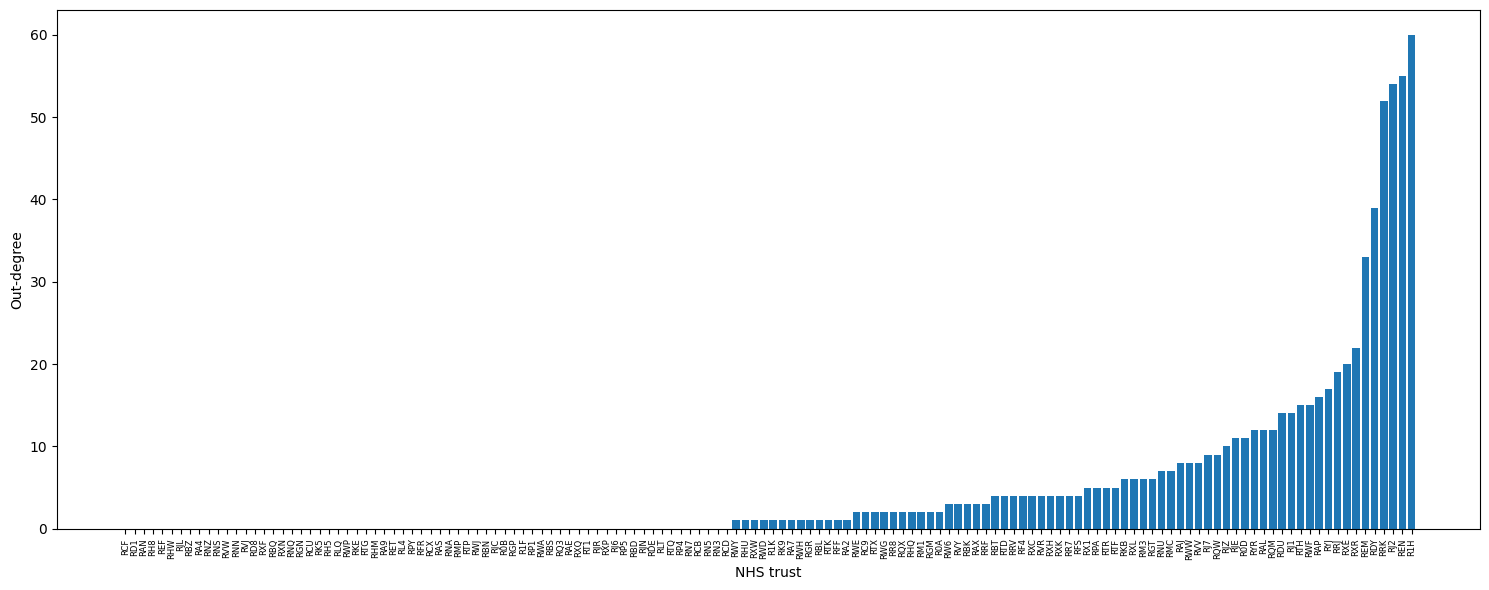

In [65]:
out_degrees = np.sum(gmm008.W != 0, axis=1)
order = np.argsort(out_degrees)

plt.figure(figsize=(15, 6))
plt.bar(covid_keys[order], out_degrees[order])
plt.xlabel("NHS trust")
plt.ylabel("Out-degree")
plt.xticks(rotation=90, fontsize=6)
plt.tight_layout()
plt.show()

In [66]:
# Print the out-degrees in increasing order, trust indices, and their codes.
print(np.sort(np.sum(gmm008.W!=0,axis=1)))
print(np.argsort(np.sum(gmm008.W!=0,axis=1)))
print(covid_keys[np.argsort(np.sum(gmm008.W!=0,axis=1))])

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  1  1  1  1  1
  1  1  1  1  1  1  1  2  2  2  2  2  2  2  2  2  2  3  3  3  3  3  4  4
  4  4  4  4  4  4  4  4  5  5  5  5  6  6  6  6  7  7  8  8  8  9  9 10
 11 11 12 12 12 14 14 15 15 16 17 19 20 22 33 39 52 54 55 60]
[  0  86  83  81  80  79  71  70 138  88  68  66  64  63  61  59  52  49
  46  67  90  92  93 137 135 133 124 118 115 114 112 110 109 108 105 104
 102 101 100  99  96  95  45  44  69  42   1   7  10  12  15  18  19  20
  22  23  25  28  34  35  36  21 139  39  37  40  13  77 113 116  54 123
 120  30 131 134   2   4  85 125   6 126 130  50  41  91  62  84  56  76
  97 128  48 136  58 106 117   3  29  31  11  89  33  17  73  57  94  72
 121   8  87  14  74   9  60 129  26  98 107  47 127 122 132  82  16  32
  38  75  55  65  43 111  78  27  53  24 119  51 103   5]
['RC

In [51]:
covid_locations[5] # London 

array([-0.056023, 51.517168])

In [54]:
covid_locations[103] # Wirral

array([-3.025849, 53.332283])

In [53]:
covid_locations[51] # London

array([-1.7917000e-02,  5.1453022e+01])

In [55]:
covid_locations[119] #Birmingham

array([-1.942563, 52.451833])

In [56]:
covid_locations[24] #Poole

array([-1.978032, 50.740063])

In [67]:
covid_locations[53] #Liverpool

array([-2.964809, 53.409523])

### Network Visualisation

#### Geo network

C:\Users\LHX\AppData\Local\Temp\ipykernel_14024\3135732607.py:36: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(


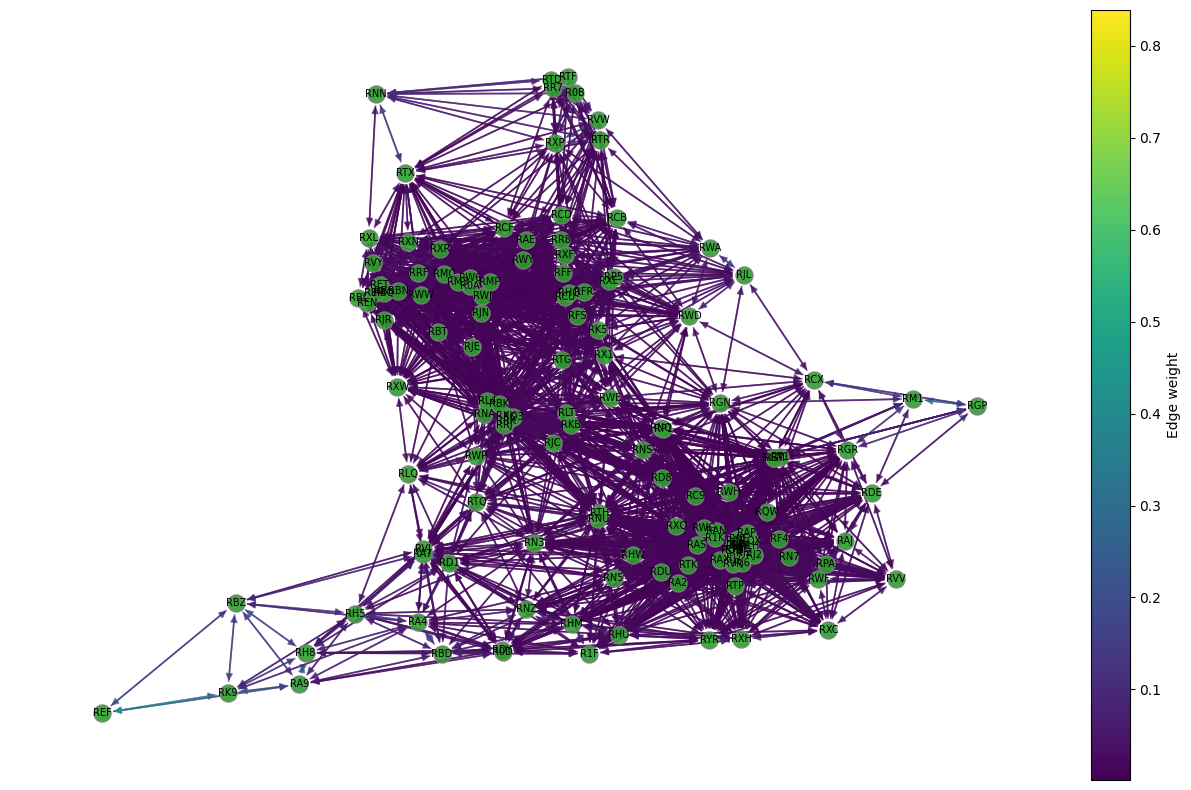

In [78]:
import networkx as nx

G = nx.from_numpy_array(covid_network.w_mats[1], create_using=nx.DiGraph)
N = gmm008.W.shape[0]

pos = {
    i: covid_locations[i]
    for i in range(N)
}

options = {"edgecolors": "tab:gray", "node_size": 150, "alpha": 0.9}
fig, ax = plt.subplots(figsize=(12, 8))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=range(N),
    node_color="tab:green",
    **options,
    ax=ax
)

nx.draw_networkx_labels(
    G, pos,
    {i: covid_keys[i] for i in range(N)},
    font_size=7,
    font_color="black",
    ax=ax
)

edgelist = list(G.edges())
edge_w = np.array(
    [G[u][v]["weight"] for u, v in edgelist],
    dtype=float
)

nx.draw_networkx_edges(
    G, pos,
    edgelist=edgelist,
    edge_color=edge_w,
    edge_cmap=plt.cm.viridis,
    edge_vmin=edge_w.min(),
    edge_vmax=edge_w.max(),
    width=1.2,
    alpha=0.7,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=10,
    ax=ax
)

sm = plt.cm.ScalarMappable(
    cmap=plt.cm.viridis,
    norm=plt.Normalize(edge_w.min(), edge_w.max())
)

cbar = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Edge weight")

ax.set_axis_off()
plt.tight_layout()
plt.show()

#### NLSWE network

C:\Users\LHX\AppData\Local\Temp\ipykernel_14024\4027693151.py:63: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  edges = nx.draw_networkx_edges(


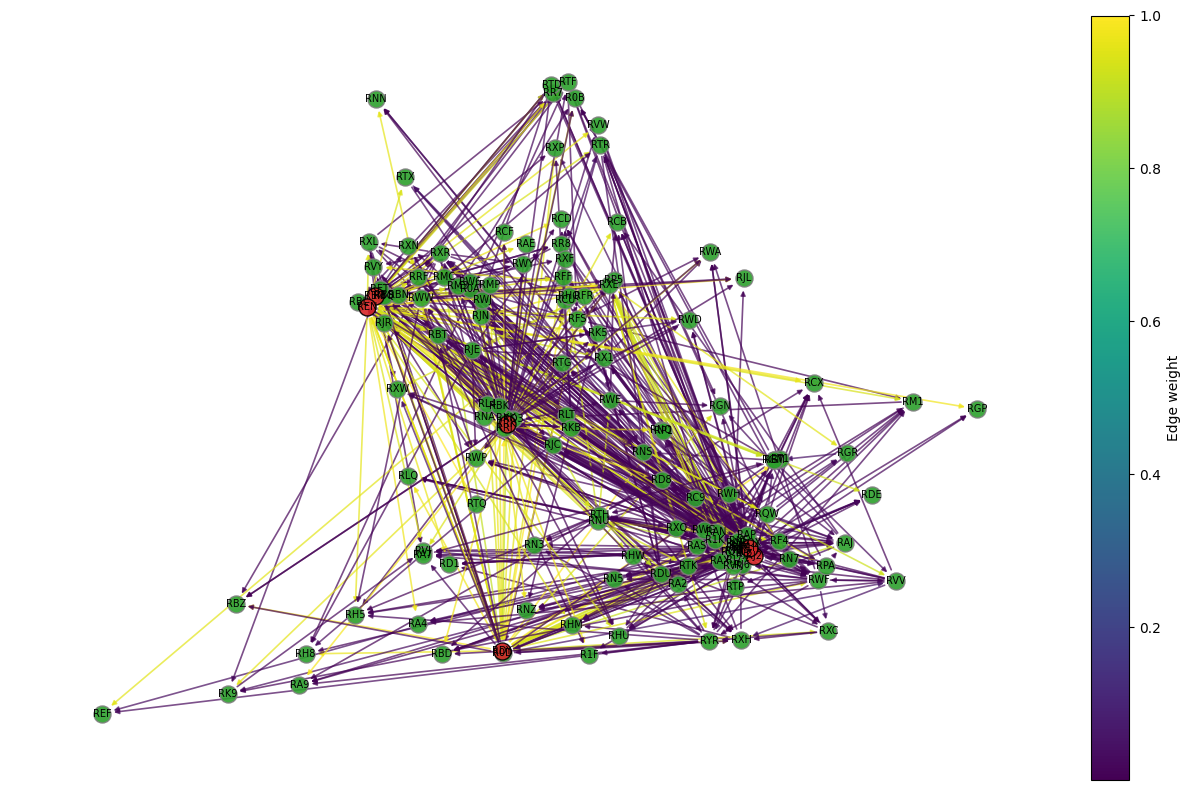

In [79]:
import networkx as nx

G = nx.from_numpy_array(gmm008.W, create_using=nx.DiGraph)
N = gmm008.W.shape[0]

out_degrees = np.sum(gmm008.W != 0, axis=1)
top6 = np.argsort(out_degrees)[-6:]
other_nodes = [i for i in range(N) if i not in top6]

pos = {
    i: covid_locations[i]
    for i in range(N)
}

fig, ax = plt.subplots(figsize=(12, 8))

nx.draw_networkx_nodes(
    G, pos,
    nodelist=other_nodes,
    node_color="tab:green",
    edgecolors="tab:gray",
    node_size=150,
    alpha=0.9,
    ax=ax
)

highlighted = nx.draw_networkx_nodes(
    G, pos,
    nodelist=top6,
    node_color="tab:red",
    edgecolors="black",
    node_size=150,
    alpha=0.9,
    ax=ax
)
highlighted.set_zorder(3)

nx.draw_networkx_labels(
    G, pos,
    {i: covid_keys[i] for i in other_nodes},
    font_size=7,
    font_color="black",
    ax=ax
)

highlighted_labels = nx.draw_networkx_labels(
    G, pos,
    {i: covid_keys[i] for i in top6},
    font_size=7,
    font_color="black",
    ax=ax
)

for label in highlighted_labels.values():
    label.set_zorder(4)

edgelist = list(G.edges())
edge_w = np.array(
    [G[u][v]["weight"] for u, v in edgelist],
    dtype=float
)

edges = nx.draw_networkx_edges(
    G, pos,
    edgelist=edgelist,
    edge_color=edge_w,
    edge_cmap=plt.cm.viridis,
    edge_vmin=edge_w.min(),
    edge_vmax=edge_w.max(),
    width=1.2,
    alpha=0.7,
    arrows=True,
    arrowstyle="-|>",
    arrowsize=7,
    ax=ax
)

for edge in edges:
    edge.set_zorder(1)

sm = plt.cm.ScalarMappable(
    cmap=plt.cm.viridis,
    norm=plt.Normalize(edge_w.min(), edge_w.max())
)

cbar = plt.colorbar(sm, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Edge weight")

ax.set_axis_off()
plt.tight_layout()
plt.show()